In [1]:

# Install the dataset download library
!pip -q install ucimlrepo

import os
import pandas as pd
from ucimlrepo import fetch_ucirepo

# Create a folder for our project datasets
os.makedirs("/content/healthcare_project/datasets", exist_ok=True)
folder = "/content/healthcare_project/datasets"

# DATASET 1: Diabetes Health Indicators
url = (
    "https://raw.githubusercontent.com/"
    "razibdash/Diabetes-Health-Indicators/main/"
    "diabetes_012_health_indicators_BRFSS2015.csv"
)

df1 = pd.read_csv(url)
df1.to_csv(
    f"{folder}/diabetes_health_indicators.csv",
    index=False
)

print("Dataset 1 downloaded successfully!")
print("Shape:", df1.shape)
print(df1.head())

# DATASET 2: Diabetes 130-US Hospitals
dataset = fetch_ucirepo(id=296)

df2 = pd.concat(
    [dataset.data.features, dataset.data.targets],
    axis=1
)

df2.to_csv(
    f"{folder}/diabetes_hospital_readmission.csv",
    index=False
)

print("\nDataset 2 downloaded successfully!")
print("Shape:", df2.shape)
print(df2.head())

print("\nFiles saved in:", folder)


Dataset 1 downloaded successfully!
Shape: (253680, 22)
   Diabetes_012  HighBP  HighChol  CholCheck   BMI  Smoker  Stroke  \
0           0.0     1.0       1.0        1.0  40.0     1.0     0.0   
1           0.0     0.0       0.0        0.0  25.0     1.0     0.0   
2           0.0     1.0       1.0        1.0  28.0     0.0     0.0   
3           0.0     1.0       0.0        1.0  27.0     0.0     0.0   
4           0.0     1.0       1.0        1.0  24.0     0.0     0.0   

   HeartDiseaseorAttack  PhysActivity  Fruits  ...  AnyHealthcare  \
0                   0.0           0.0     0.0  ...            1.0   
1                   0.0           1.0     0.0  ...            0.0   
2                   0.0           0.0     1.0  ...            1.0   
3                   0.0           1.0     1.0  ...            1.0   
4                   0.0           1.0     1.0  ...            1.0   

   NoDocbcCost  GenHlth  MentHlth  PhysHlth  DiffWalk  Sex   Age  Education  \
0          0.0      5.0      1

/usr/local/lib/python3.13/dist-packages/ucimlrepo/fetch.py:97: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)



Dataset 2 downloaded successfully!
Shape: (101766, 48)
              race  gender      age weight  admission_type_id  \
0        Caucasian  Female   [0-10)    NaN                  6   
1        Caucasian  Female  [10-20)    NaN                  1   
2  AfricanAmerican  Female  [20-30)    NaN                  1   
3        Caucasian    Male  [30-40)    NaN                  1   
4        Caucasian    Male  [40-50)    NaN                  1   

   discharge_disposition_id  admission_source_id  time_in_hospital payer_code  \
0                        25                    1                 1        NaN   
1                         1                    7                 3        NaN   
2                         1                    7                 2        NaN   
3                         1                    7                 2        NaN   
4                         1                    7                 1        NaN   

          medical_specialty  ...  citoglipton  insulin  glyburide-

In [2]:

import os

folder = "/content/healthcare_project/datasets"

for filename in os.listdir(folder):
    path = os.path.join(folder, filename)
    print(f"{filename}: {os.path.getsize(path) / (1024**2):.2f} MB")


diabetes_health_indicators.csv: 21.68 MB
diabetes_hospital_readmission.csv: 15.49 MB


In [3]:

!pip -q install ucimlrepo shap xgboost

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, VotingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    RocCurveDisplay
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")


Libraries imported successfully.


In [4]:

folder = "/content/healthcare_project/datasets"

df_diabetes = pd.read_csv(
    f"{folder}/diabetes_health_indicators.csv"
)
df_hospital = pd.read_csv(
    f"{folder}/diabetes_hospital_readmission.csv"
)

print("DATASET 1: DIABETES HEALTH INDICATORS")
print("Shape:", df_diabetes.shape)
print("Columns:", df_diabetes.columns.tolist())
display(df_diabetes.head())

print("\nDATASET 2: HOSPITAL READMISSION")
print("Shape:", df_hospital.shape)
print("Columns:", df_hospital.columns.tolist())
display(df_hospital.head())

print("\nMissing values in Dataset 1:", df_diabetes.isna().sum().sum())
print("Missing values in Dataset 2:", df_hospital.isna().sum().sum())



DATASET 1: DIABETES HEALTH INDICATORS
Shape: (253680, 22)
Columns: ['Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0



DATASET 2: HOSPITAL READMISSION
Shape: (101766, 48)
Columns: ['race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']


,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,...,No,No,No,No,No,No,No,No,No,NO
1,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,...,No,No,No,No,No,No,No,No,Yes,NO
3,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,...,No,Steady,No,No,No,No,No,Ch,Yes,NO



Missing values in Dataset 1: 0
Missing values in Dataset 2: 374017


In [5]:

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

folder = "/content/healthcare_project/datasets"

print("Files available:", os.listdir(folder))

df_diabetes = pd.read_csv(
    f"{folder}/diabetes_health_indicators.csv"
)

df_hospital = pd.read_csv(
    f"{folder}/diabetes_hospital_readmission.csv"
)

print("Diabetes dataset shape:", df_diabetes.shape)
print("Hospital dataset shape:", df_hospital.shape)
print("Datasets loaded successfully!")


Files available: ['diabetes_health_indicators.csv', 'diabetes_hospital_readmission.csv']
Diabetes dataset shape: (253680, 22)
Hospital dataset shape: (101766, 48)
Datasets loaded successfully!


Diabetes class distribution:
Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64


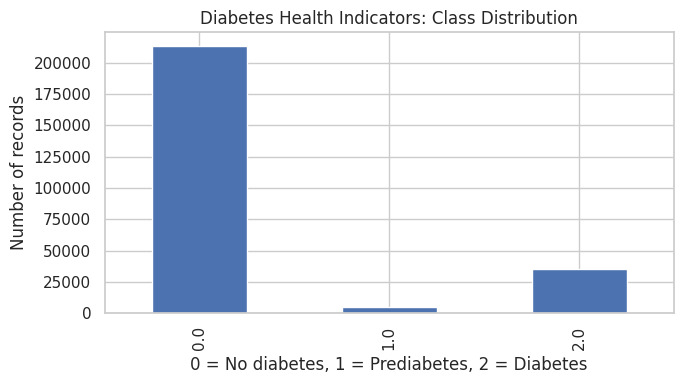


Hospital readmission distribution:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


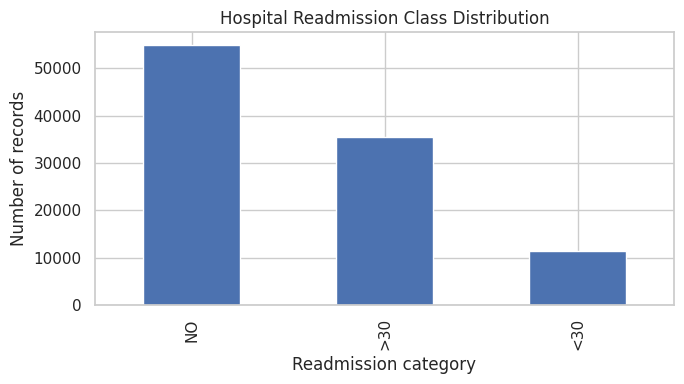

In [6]:

target1 = "Diabetes_012"

print("Diabetes class distribution:")
print(df_diabetes[target1].value_counts().sort_index())

df_diabetes[target1].value_counts().sort_index().plot(
    kind="bar", figsize=(7, 4)
)

plt.title("Diabetes Health Indicators: Class Distribution")
plt.xlabel("0 = No diabetes, 1 = Prediabetes, 2 = Diabetes")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

target2 = "readmitted"

print("\nHospital readmission distribution:")
print(df_hospital[target2].value_counts(dropna=False))

df_hospital[target2].value_counts(dropna=False).plot(
    kind="bar", figsize=(7, 4)
)

plt.title("Hospital Readmission Class Distribution")
plt.xlabel("Readmission category")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()


In [7]:

# DATA PREPROCESSING: INITIAL DATA QUALITY CHECK

for name, df in [
    ("Diabetes Health Indicators", df_diabetes),
    ("Hospital Readmission", df_hospital)
]:
    print(f"\n{'=' * 50}")
    print(name)
    print("=" * 50)

    print("Number of records:", df.shape[0])
    print("Number of attributes:", df.shape[1])
    print("Duplicate rows:", df.duplicated().sum())
    print("Total missing values:", df.isna().sum().sum())

    missing = df.isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)

    if len(missing) > 0:
        print("\nColumns with missing values:")
        print(missing.head(15))
    else:
        print("No missing values detected.")

print("\nInitial data quality check completed.")



Diabetes Health Indicators
Number of records: 253680
Number of attributes: 22
Duplicate rows: 23899
Total missing values: 0
No missing values detected.

Hospital Readmission
Number of records: 101766
Number of attributes: 48
Duplicate rows: 0
Total missing values: 374017

Columns with missing values:
weight               98569
max_glu_serum        96420
A1Cresult            84748
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
dtype: int64

Initial data quality check completed.


In [8]:

# STEP 5: DATA CLEANING

# Work on copies so the original data remains available
df_diabetes_clean = df_diabetes.copy()
df_hospital_clean = df_hospital.copy()

# 1. Remove exact duplicate records from diabetes dataset
before_diabetes = len(df_diabetes_clean)

df_diabetes_clean = (
    df_diabetes_clean
    .drop_duplicates()
    .reset_index(drop=True)
)

print("DIABETES DATASET")
print("Records before cleaning:", before_diabetes)
print("Records after removing duplicates:", len(df_diabetes_clean))
print("Duplicate records removed:",
      before_diabetes - len(df_diabetes_clean))

# 2. Convert hospital dataset's '?' markers into missing values
df_hospital_clean = df_hospital_clean.replace(
    r"^\s*\?\s*$", np.nan, regex=True
)

# 3. Check for duplicates without deleting any additional records
print("\nHOSPITAL DATASET")
print("Records:", len(df_hospital_clean))
print("Duplicate records:", df_hospital_clean.duplicated().sum())
print("Missing values after handling '?':",
      df_hospital_clean.isna().sum().sum())

# 4. Display the cleaned dataset dimensions
print("\nCLEANED DATASET DIMENSIONS")
print("Diabetes:", df_diabetes_clean.shape)
print("Hospital:", df_hospital_clean.shape)


DIABETES DATASET
Records before cleaning: 253680
Records after removing duplicates: 229781
Duplicate records removed: 23899

HOSPITAL DATASET
Records: 101766
Duplicate records: 0
Missing values after handling '?': 374017

CLEANED DATASET DIMENSIONS
Diabetes: (229781, 22)
Hospital: (101766, 48)


In [9]:

# STEP 6: DEFINE TARGETS AND SPLIT DATA

from sklearn.model_selection import train_test_split

# Dataset 1: Diabetes status
target1 = "Diabetes_012"

X1 = df_diabetes_clean.drop(columns=[target1])
y1 = df_diabetes_clean[target1].astype(int)

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1,
    test_size=0.20,
    random_state=42,
    stratify=y1
)

# Dataset 2: Early readmission
target2 = "readmitted"

df2 = df_hospital_clean.copy()

# Convert original readmission labels to a binary target
y2 = (df2[target2].astype(str).str.strip() == "<30").astype(int)

# Remove the target and patient/encounter identifiers from predictors
drop_cols = [target2]
for col in ["encounter_id", "patient_nbr"]:
    if col in df2.columns:
        drop_cols.append(col)

X2 = df2.drop(columns=drop_cols)

# Identify feature types
numeric_cols2 = X2.select_dtypes(include=np.number).columns.tolist()
categorical_cols2 = X2.select_dtypes(exclude=np.number).columns.tolist()

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2,
    test_size=0.20,
    random_state=42,
    stratify=y2
)

print("Dataset 1 — Diabetes status")
print("Training records:", len(X1_train))
print("Testing records:", len(X1_test))
print("Number of features:", X1.shape[1])

print("\nDataset 2 — Early readmission")
print("Training records:", len(X2_train))
print("Testing records:", len(X2_test))
print("Number of features:", X2.shape[1])

print("\nTarget distribution — Dataset 1")
print(y1.value_counts(normalize=True).sort_index().round(3))

print("\nTarget distribution — Dataset 2")
print(y2.value_counts(normalize=True).round(3))


Dataset 1 — Diabetes status
Training records: 183824
Testing records: 45957
Number of features: 21

Dataset 2 — Early readmission
Training records: 81412
Testing records: 20354
Number of features: 47

Target distribution — Dataset 1
Diabetes_012
0    0.827
1    0.020
2    0.153
Name: proportion, dtype: float64

Target distribution — Dataset 2
readmitted
0    0.888
1    0.112
Name: proportion, dtype: float64


In [10]:

# STEP 7: PREPROCESSING PIPELINES

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

def make_preprocessor(X):
    numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
    categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        ))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_cols),
        ("categorical", categorical_pipeline, categorical_cols)
    ])

    return preprocessor

preprocessor1 = make_preprocessor(X1_train)
preprocessor2 = make_preprocessor(X2_train)

print("Preprocessing pipelines created.")
print("Dataset 1 numeric features:",
      len(X1_train.select_dtypes(include=np.number).columns))
print("Dataset 2 numeric features:",
      len(numeric_cols2))
print("Dataset 2 categorical features:",
      len(categorical_cols2))


Preprocessing pipelines created.
Dataset 1 numeric features: 21
Dataset 2 numeric features: 11
Dataset 2 categorical features: 36


In [11]:

# STEP 8: DEFINE MODELS

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, VotingClassifier

def build_models(preprocessor):
    logistic = Pipeline([
        ("preprocess", preprocessor),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ])

    random_forest = Pipeline([
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])

    extra_trees = Pipeline([
        ("preprocess", preprocessor),
        ("model", ExtraTreesClassifier(
            n_estimators=100,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])

    ensemble = VotingClassifier(
        estimators=[
            ("lr", logistic),
            ("rf", random_forest),
            ("et", extra_trees)
        ],
        voting="soft",
        weights=[1, 2, 2],
        n_jobs=1
    )

    return {
        "Logistic Regression": logistic,
        "Random Forest": random_forest,
        "Extra Trees": extra_trees,
        "Proposed Ensemble": ensemble
    }

models1 = build_models(preprocessor1)
models2 = build_models(preprocessor2)

print("Four models prepared for each dataset.")


Four models prepared for each dataset.


Training Logistic Regression: Diabetes Status
              precision    recall  f1-score   support

           0       0.94      0.64      0.77     38012
           1       0.03      0.30      0.06       926
           2       0.37      0.59      0.45      7019

    accuracy                           0.63     45957
   macro avg       0.45      0.51      0.43     45957
weighted avg       0.84      0.63      0.70     45957



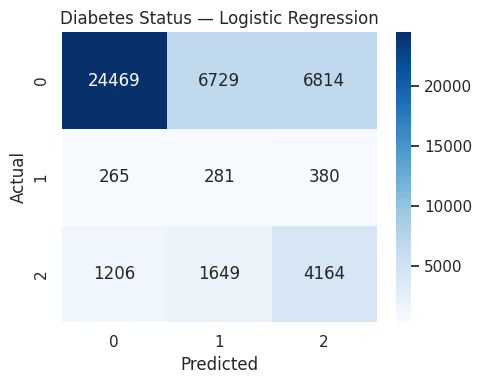

Training Random Forest: Diabetes Status
              precision    recall  f1-score   support

           0       0.84      0.97      0.90     38012
           1       0.01      0.00      0.00       926
           2       0.45      0.15      0.23      7019

    accuracy                           0.82     45957
   macro avg       0.44      0.37      0.38     45957
weighted avg       0.77      0.82      0.78     45957



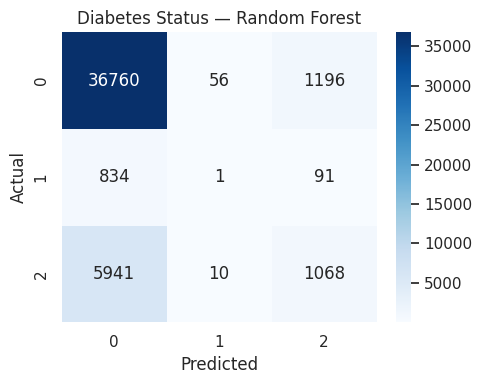

Training Extra Trees: Diabetes Status
              precision    recall  f1-score   support

           0       0.85      0.95      0.89     38012
           1       0.02      0.00      0.01       926
           2       0.39      0.17      0.24      7019

    accuracy                           0.81     45957
   macro avg       0.42      0.38      0.38     45957
weighted avg       0.76      0.81      0.78     45957



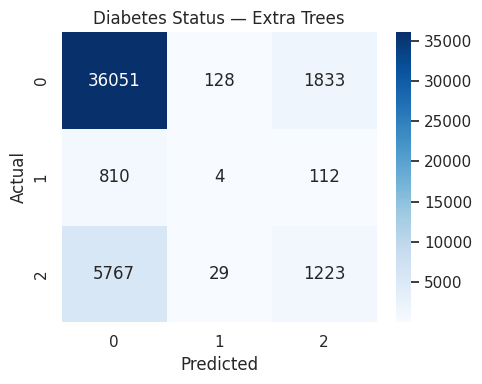

Training Proposed Ensemble: Diabetes Status
              precision    recall  f1-score   support

           0       0.85      0.95      0.90     38012
           1       0.02      0.00      0.00       926
           2       0.45      0.23      0.31      7019

    accuracy                           0.82     45957
   macro avg       0.44      0.39      0.40     45957
weighted avg       0.77      0.82      0.79     45957



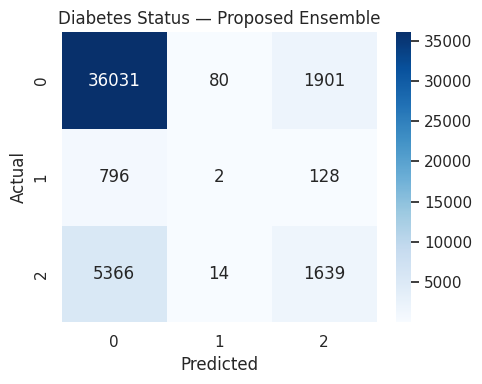

Training Logistic Regression: 30-Day Readmission
              precision    recall  f1-score   support

           0       0.92      0.65      0.76     18083
           1       0.17      0.55      0.25      2271

    accuracy                           0.64     20354
   macro avg       0.54      0.60      0.51     20354
weighted avg       0.84      0.64      0.71     20354



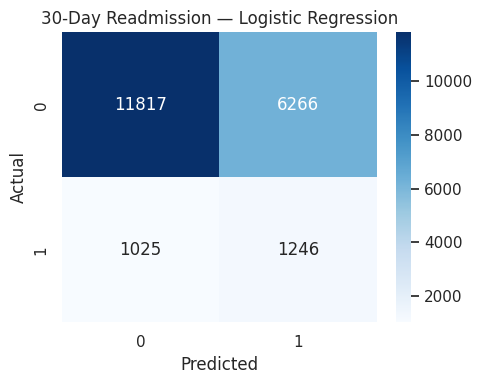

Training Random Forest: 30-Day Readmission
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     18083
           1       0.63      0.01      0.01      2271

    accuracy                           0.89     20354
   macro avg       0.76      0.50      0.48     20354
weighted avg       0.86      0.89      0.84     20354



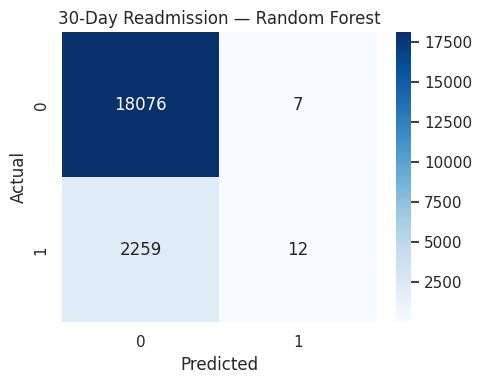

Training Extra Trees: 30-Day Readmission
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     18083
           1       0.56      0.01      0.03      2271

    accuracy                           0.89     20354
   macro avg       0.73      0.51      0.48     20354
weighted avg       0.85      0.89      0.84     20354



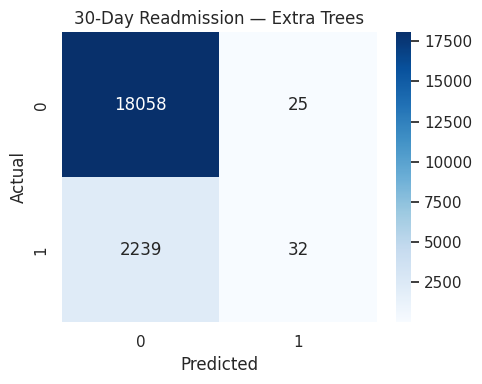

Training Proposed Ensemble: 30-Day Readmission
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     18083
           1       0.62      0.02      0.03      2271

    accuracy                           0.89     20354
   macro avg       0.75      0.51      0.49     20354
weighted avg       0.86      0.89      0.84     20354



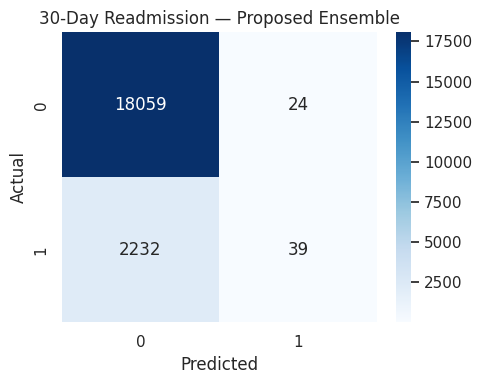

,Dataset,Model,Accuracy,Precision_macro,Recall_macro,F1_macro,ROC_AUC,Specificity
0,Diabetes Status,Logistic Regression,0.6292,0.4475,0.5135,0.4257,0.7607,NaN
1,Diabetes Status,Random Forest,0.8231,0.4376,0.3734,0.3771,0.7142,NaN
2,Diabetes Status,Extra Trees,0.8111,0.4189,0.3757,0.3805,0.6920,NaN
3,Diabetes Status,Proposed Ensemble,0.8197,0.4405,0.3945,0.4030,0.7398,NaN
4,30-Day Readmission,Logistic Regression,0.6418,0.5430,0.6011,0.5095,0.6440,0.6535
5,30-Day Readmission,Random Forest,0.8887,0.7602,0.5024,0.4757,0.6511,0.9996
6,30-Day Readmission,Extra Trees,0.8888,0.7255,0.5064,0.4843,0.6345,0.9986
7,30-Day Readmission,Proposed Ensemble,0.8892,0.7545,0.5079,0.4873,0.6653,0.9987


In [12]:

# STEP 9: MODEL TRAINING AND EVALUATION

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

def evaluate_models(models, X_train, X_test, y_train, y_test, task_name):
    results = []
    fitted_models = {}

    for name, model in models.items():
        print(f"Training {name}: {task_name}")
        model.fit(X_train, y_train)
        fitted_models[name] = model

        predictions = model.predict(X_test)
        probabilities = model.predict_proba(X_test)

        row = {
            "Dataset": task_name,
            "Model": name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision_macro": precision_score(
                y_test, predictions, average="macro", zero_division=0
            ),
            "Recall_macro": recall_score(
                y_test, predictions, average="macro", zero_division=0
            ),
            "F1_macro": f1_score(
                y_test, predictions, average="macro", zero_division=0
            )
        }

        if len(model.classes_) == 2:
            positive_index = list(model.classes_).index(1)
            row["ROC_AUC"] = roc_auc_score(
                y_test, probabilities[:, positive_index]
            )

            tn, fp, fn, tp = confusion_matrix(
                y_test, predictions, labels=[0, 1]
            ).ravel()

            row["Specificity"] = tn / (tn + fp) if (tn + fp) else 0
        else:
            row["ROC_AUC"] = roc_auc_score(
                y_test,
                probabilities,
                labels=model.classes_,
                multi_class="ovr",
                average="macro"
            )
            row["Specificity"] = np.nan

        results.append(row)

        print(classification_report(
            y_test, predictions, zero_division=0
        ))

        cm = confusion_matrix(y_test, predictions)
        plt.figure(figsize=(5, 4))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
        plt.title(f"{task_name} — {name}")
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.tight_layout()
        plt.show()

    return pd.DataFrame(results), fitted_models

results1, fitted1 = evaluate_models(
    models1, X1_train, X1_test, y1_train, y1_test,
    "Diabetes Status"
)

results2, fitted2 = evaluate_models(
    models2, X2_train, X2_test, y2_train, y2_test,
    "30-Day Readmission"
)

results = pd.concat([results1, results2], ignore_index=True)

display(results.round(4))


Balanced Random Forest — Early Readmission
              precision    recall  f1-score   support

           0       0.90      0.93      0.92     18083
           1       0.27      0.20      0.23      2271

    accuracy                           0.85     20354
   macro avg       0.59      0.57      0.57     20354
weighted avg       0.83      0.85      0.84     20354

ROC-AUC: 0.671


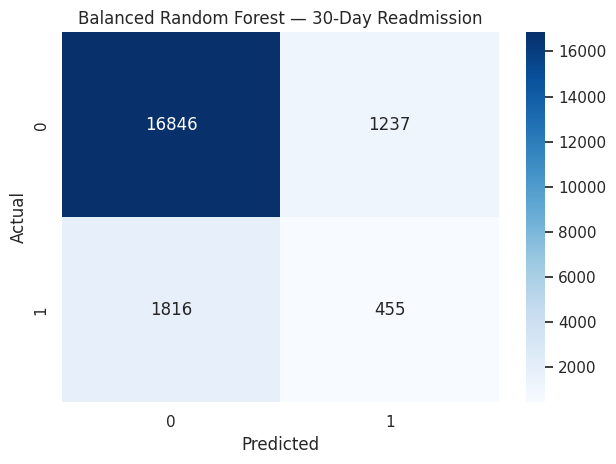

In [13]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Class-weighted Random Forest for early readmission
rf_balanced = Pipeline([
    ("preprocess", make_preprocessor(X2_train)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ))
])

rf_balanced.fit(X2_train, y2_train)

pred = rf_balanced.predict(X2_test)
proba = rf_balanced.predict_proba(X2_test)

print("Balanced Random Forest — Early Readmission")
print(classification_report(
    y2_test, pred, zero_division=0
))

print("ROC-AUC:", round(
    roc_auc_score(y2_test, proba[:, 1]), 4
))

cm = confusion_matrix(y2_test, pred, labels=[0, 1])

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Balanced Random Forest — 30-Day Readmission")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


In [14]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

models_to_compare = {
    "Original Ensemble": fitted2["Proposed Ensemble"],
    "Balanced Random Forest": rf_balanced
}

comparison = []

for name, model in models_to_compare.items():
    predictions = model.predict(X2_test)
    probabilities = model.predict_proba(X2_test)

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y2_test, predictions),
        "Early Readmission Precision": precision_score(
            y2_test, predictions, pos_label=1, zero_division=0
        ),
        "Early Readmission Recall": recall_score(
            y2_test, predictions, pos_label=1, zero_division=0
        ),
        "Early Readmission F1": f1_score(
            y2_test, predictions, pos_label=1, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y2_test, probabilities[:, 1])
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(4))


,Model,Accuracy,Early Readmission Precision,Early Readmission Recall,Early Readmission F1,ROC-AUC
0,Original Ensemble,0.8892,0.6190,0.0172,0.0334,0.6653
1,Balanced Random Forest,0.8500,0.2689,0.2004,0.2296,0.6710


In [22]:

import shap
import numpy as np
import matplotlib.pyplot as plt

def fast_shap(fitted_models, X_train, X_test, title):

    # Select the trained Random Forest pipeline
    pipeline = fitted_models["Random Forest"]

    prep = pipeline.named_steps["preprocess"]
    model = pipeline.named_steps["model"]

    # Use small samples to reduce computation
    background = X_train.sample(
        n=min(30, len(X_train)),
        random_state=42
    )

    sample = X_test.sample(
        n=min(50, len(X_test)),
        random_state=42
    )

    # Apply the already-fitted preprocessing pipeline
    background_t = prep.transform(background)
    sample_t = prep.transform(sample)

    # Convert sparse matrices if necessary
    if hasattr(background_t, "toarray"):
        background_t = background_t.toarray()

    if hasattr(sample_t, "toarray"):
        sample_t = sample_t.toarray()

    names = prep.get_feature_names_out()

    # Explain the positive-class probability
    def predict_positive(X):
        return model.predict_proba(X)[:, 1]

    # Create a small independent background masker
    masker = shap.maskers.Independent(
        background_t,
        max_samples=30
    )

    explainer = shap.Explainer(
        predict_positive,
        masker,
        algorithm="permutation"
    )

    explanation = explainer(
        sample_t,
        max_evals=2 * sample_t.shape[1] + 1
    )

    # Extract SHAP values robustly
    values = np.asarray(explanation.values)

    # Expected shape for binary positive-class probabilities:
    # (number of samples, number of features)
    if values.ndim == 3:
        values = values[:, :, -1]

    if values.ndim != 2:
        raise ValueError(
            f"Unexpected SHAP output shape: {values.shape}"
        )

    # Average absolute contribution across explained samples
    importance = np.abs(values).mean(axis=0)

    # Sort features by importance
    order = np.argsort(importance)[-15:]

    plt.figure(figsize=(10, 7))

    plt.barh(
        np.asarray(names)[order],
        importance[order]
    )

    plt.xlabel("Mean Absolute SHAP Value")
    plt.ylabel("Feature")
    plt.title(title)
    plt.tight_layout()
    plt.show()


PermutationExplainer explainer: 51it [03:12,  4.01s/it]


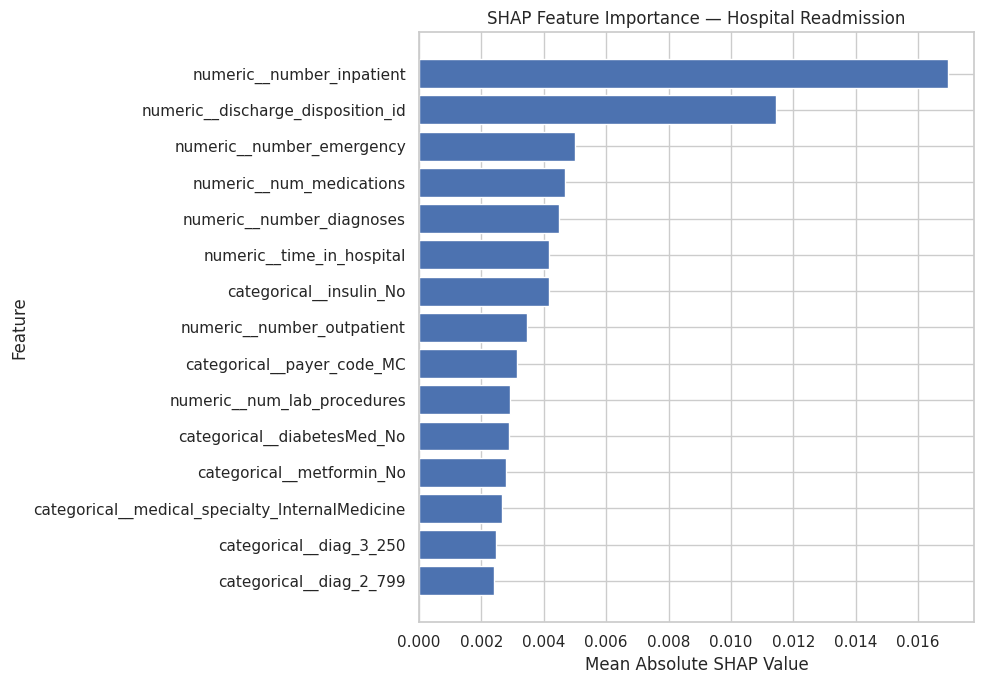

In [23]:

fast_shap(
    fitted2,
    X2_train,
    X2_test,
    "SHAP Feature Importance — Hospital Readmission"
)


In [25]:
import shap
import numpy as np
import matplotlib.pyplot as plt

def fast_shap_fixed(fitted_models, X_train, X_test, title):
    pipeline = fitted_models["Random Forest"]
    prep = pipeline.named_steps["preprocess"]
    model = pipeline.named_steps["model"]

    background = X_train.sample(
        n=min(10, len(X_train)),
        random_state=42
    )
    sample = X_test.sample(
        n=min(20, len(X_test)),
        random_state=42
    )

    background_t = prep.transform(background)
    sample_t = prep.transform(sample)

    if hasattr(background_t, "toarray"):
        background_t = background_t.toarray()
    if hasattr(sample_t, "toarray"):
        sample_t = sample_t.toarray()

    names = prep.get_feature_names_out()

    explainer = shap.Explainer(
        lambda X: model.predict_proba(X)[:, 1],
        shap.maskers.Independent(background_t),
        algorithm="permutation"
    )

    explanation = explainer(
        sample_t,
        max_evals=2 * sample_t.shape[1] + 1
    )

    importance = np.abs(explanation.values).mean(axis=0)
    order = np.argsort(importance)[-15:]

    plt.figure(figsize=(10, 7))
    plt.barh(np.asarray(names)[order], importance[order])
    plt.xlabel("Mean Absolute SHAP Value")
    plt.title(title)
    plt.tight_layout()
    plt.show()

PermutationExplainer explainer: 21it [00:47,  2.79s/it]


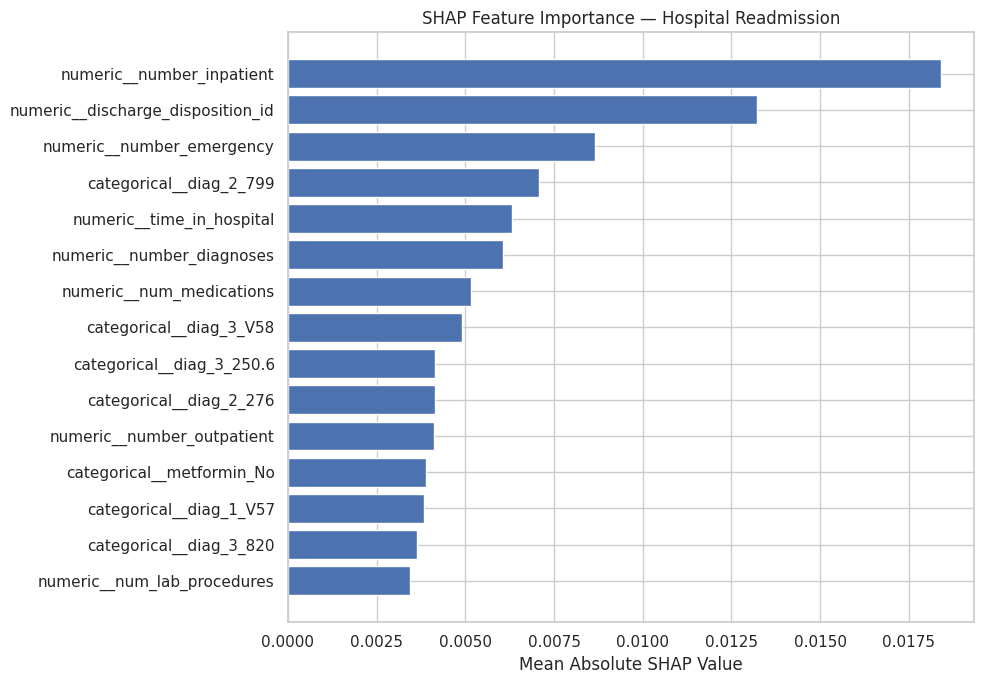

In [26]:
fast_shap_fixed(
    fitted2,
    X2_train,
    X2_test,
    "SHAP Feature Importance — Hospital Readmission"
)

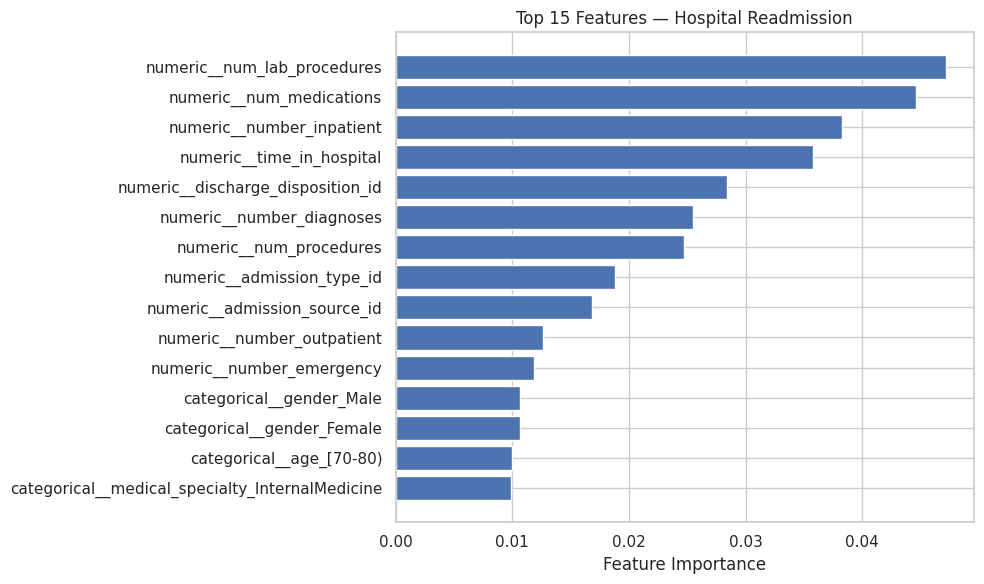

,Feature,Importance
4,numeric__num_lab_procedures,0.047226
6,numeric__num_medications,0.044606
9,numeric__number_inpatient,0.038277
3,numeric__time_in_hospital,0.035815
1,numeric__discharge_disposition_id,0.028418
10,numeric__number_diagnoses,0.025501
5,numeric__num_procedures,0.024693
0,numeric__admission_type_id,0.018849
2,numeric__admission_source_id,0.016800
7,numeric__number_outpatient,0.012650


In [27]:

# Hospital Readmission: Feature Importance
# Faster alternative to SHAP

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

rf_pipeline = fitted2["Random Forest"]

preprocessor = rf_pipeline.named_steps["preprocess"]
rf_model = rf_pipeline.named_steps["model"]

feature_names = preprocessor.get_feature_names_out()
importances = rf_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.title("Top 15 Features — Hospital Readmission")
plt.tight_layout()
plt.show()

display(importance_df.head(15))


In [28]:

import os
import joblib
import pandas as pd

output_dir = "/content/healthcare_project/results"
os.makedirs(output_dir, exist_ok=True)

# Save model comparison results
results.to_csv(
    f"{output_dir}/model_comparison_results.csv",
    index=False
)

comparison_df.to_csv(
    f"{output_dir}/readmission_model_comparison.csv",
    index=False
)

# Save trained models
joblib.dump(
    fitted1["Proposed Ensemble"],
    f"{output_dir}/diabetes_ensemble.joblib"
)

joblib.dump(
    fitted2["Proposed Ensemble"],
    f"{output_dir}/readmission_ensemble.joblib"
)

joblib.dump(
    rf_balanced,
    f"{output_dir}/balanced_readmission_random_forest.joblib"
)

# Save hospital feature importance
importance_df.to_csv(
    f"{output_dir}/hospital_feature_importance.csv",
    index=False
)

print("Project results saved successfully:")
for filename in sorted(os.listdir(output_dir)):
    print("-", filename)


Project results saved successfully:
- balanced_readmission_random_forest.joblib
- diabetes_ensemble.joblib
- hospital_feature_importance.csv
- model_comparison_results.csv
- readmission_ensemble.joblib
- readmission_model_comparison.csv


,Threshold,Precision,Recall,F1-score
0,0.10,0.1117,1.0000,0.2009
1,0.15,0.1121,1.0000,0.2016
2,0.20,0.1140,0.9921,0.2045
3,0.25,0.1213,0.9604,0.2153
4,0.30,0.1340,0.8741,0.2324
5,0.35,0.1561,0.7424,0.2579
6,0.40,0.1844,0.5469,0.2758
7,0.45,0.2226,0.3549,0.2736
8,0.50,0.2689,0.2004,0.2296
9,0.55,0.3260,0.0916,0.1430


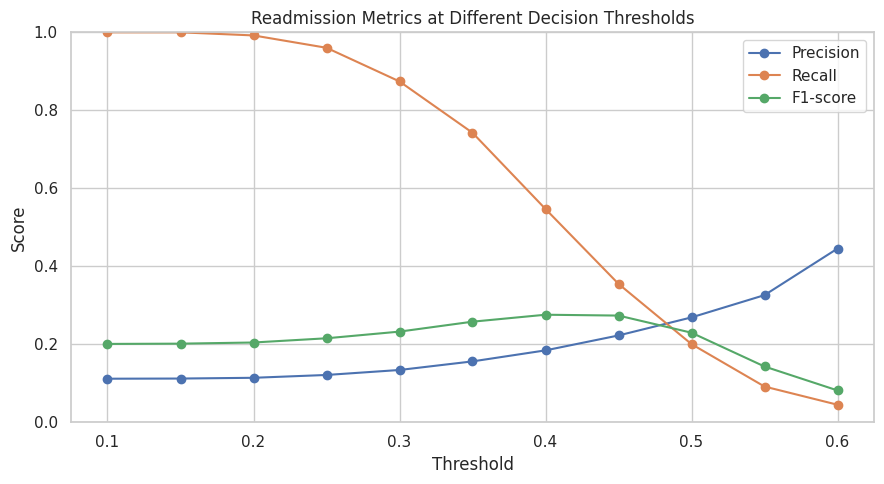

In [29]:

import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

# Use the already-trained balanced Random Forest
probabilities = rf_balanced.predict_proba(X2_test)

positive_index = list(rf_balanced.classes_).index(1)
early_readmission_prob = probabilities[:, positive_index]

threshold_results = []

for threshold in np.arange(0.10, 0.61, 0.05):
    predictions = (
        early_readmission_prob >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y2_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y2_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y2_test, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

threshold_df.set_index("Threshold")[
    ["Precision", "Recall", "F1-score"]
].plot(
    marker="o",
    figsize=(9, 5)
)

plt.title("Readmission Metrics at Different Decision Thresholds")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(True)
plt.tight_layout()
plt.show()


In [30]:

from sklearn.metrics import classification_report
import pandas as pd

diabetes_ensemble = fitted1["Proposed Ensemble"]

diabetes_predictions = diabetes_ensemble.predict(X1_test)

print("Diabetes Ensemble — Per-Class Evaluation")
print(classification_report(
    y1_test,
    diabetes_predictions,
    labels=[0, 1, 2],
    target_names=[
        "No Diabetes",
        "Prediabetes",
        "Diabetes"
    ],
    zero_division=0
))

print("\nClass distribution in test set:")
print(y1_test.value_counts().sort_index())


Diabetes Ensemble — Per-Class Evaluation
              precision    recall  f1-score   support

 No Diabetes       0.85      0.95      0.90     38012
 Prediabetes       0.02      0.00      0.00       926
    Diabetes       0.45      0.23      0.31      7019

    accuracy                           0.82     45957
   macro avg       0.44      0.39      0.40     45957
weighted avg       0.77      0.82      0.79     45957


Class distribution in test set:
Diabetes_012
0    38012
1      926
2     7019
Name: count, dtype: int64


In [31]:

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, accuracy_score

# Class-weighted baseline to address class imbalance
diabetes_balanced_lr = Pipeline([
    ("preprocess", clone(preprocessor1)),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

diabetes_balanced_lr.fit(X1_train, y1_train)

pred_lr = diabetes_balanced_lr.predict(X1_test)
pred_ensemble = fitted1["Proposed Ensemble"].predict(X1_test)

print("CLASS-WEIGHTED LOGISTIC REGRESSION")
print(classification_report(
    y1_test, pred_lr, zero_division=0
))

print("MODEL COMPARISON")
print("Metric                 Balanced LR    Ensemble")
print(f"Accuracy               {accuracy_score(y1_test, pred_lr):.4f}       "
      f"{accuracy_score(y1_test, pred_ensemble):.4f}")
print(f"Macro F1               {f1_score(y1_test, pred_lr, average='macro'):.4f}       "
      f"{f1_score(y1_test, pred_ensemble, average='macro'):.4f}")


CLASS-WEIGHTED LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.94      0.64      0.77     38012
           1       0.03      0.30      0.06       926
           2       0.37      0.59      0.45      7019

    accuracy                           0.63     45957
   macro avg       0.45      0.51      0.43     45957
weighted avg       0.84      0.63      0.70     45957

MODEL COMPARISON
Metric                 Balanced LR    Ensemble
Accuracy               0.6292       0.8197
Macro F1               0.4257       0.4030


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,0.6292,0.4475,0.5135,0.4257
4,Balanced Logistic Regression,0.6292,0.4475,0.5135,0.4257
3,Original Ensemble,0.8197,0.4405,0.3945,0.4030
2,Extra Trees,0.8111,0.4189,0.3757,0.3805
1,Random Forest,0.8231,0.4376,0.3734,0.3771


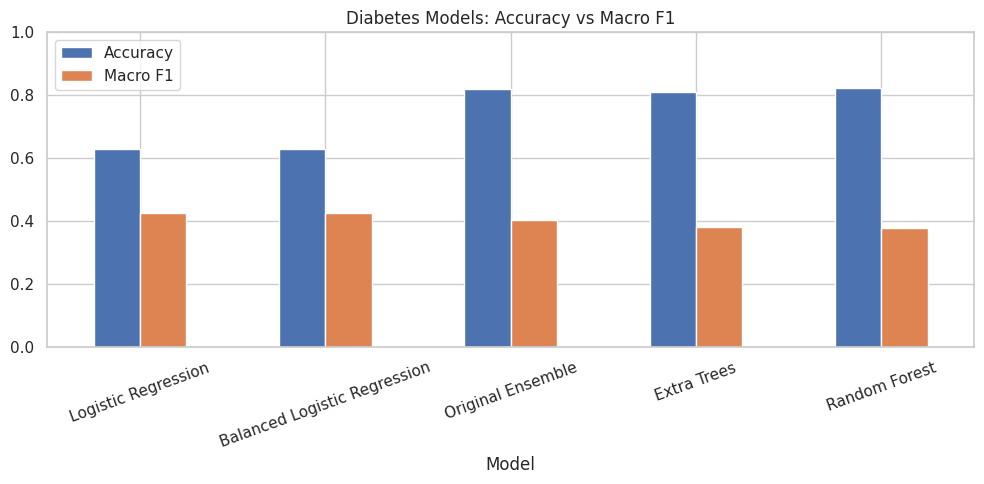

In [32]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)
import pandas as pd
import matplotlib.pyplot as plt

diabetes_models = {
    "Logistic Regression": fitted1["Logistic Regression"],
    "Random Forest": fitted1["Random Forest"],
    "Extra Trees": fitted1["Extra Trees"],
    "Original Ensemble": fitted1["Proposed Ensemble"],
    "Balanced Logistic Regression": diabetes_balanced_lr
}

rows = []

for name, model in diabetes_models.items():
    pred = model.predict(X1_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y1_test, pred),
        "Macro Precision": precision_score(
            y1_test, pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y1_test, pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y1_test, pred, average="macro", zero_division=0
        )
    })

diabetes_comparison = pd.DataFrame(rows).sort_values(
    "Macro F1", ascending=False
)

display(diabetes_comparison.round(4))

diabetes_comparison.plot(
    x="Model",
    y=["Accuracy", "Macro F1"],
    kind="bar",
    figsize=(10, 5),
    rot=20
)

plt.title("Diabetes Models: Accuracy vs Macro F1")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


In [33]:

from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=42
)

candidates = {
    "Logistic Regression": fitted1["Logistic Regression"],
    "Random Forest": fitted1["Random Forest"],
    "Extra Trees": fitted1["Extra Trees"],
    "Weighted Ensemble": fitted1["Proposed Ensemble"],
    "Balanced Logistic Regression": diabetes_balanced_lr
}

cv_results = []

for name, model in candidates.items():
    scores = cross_val_score(
        model,
        X1_train,
        y1_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=1
    )
    cv_results.append({
        "Model": name,d
        "Mean CV Macro F1": scores.mean(),
        "Std CV Macro F1": scores.std()
    })
    print(name, ":", scores.round(4))

cv_results_df = pd.DataFrame(cv_results).sort_values(
    "Mean CV Macro F1", ascending=False
)

display(cv_results_df.round(4))


Logistic Regression : [0.4187 0.4212 0.4234]
Random Forest : [0.378  0.3767 0.3756]
Extra Trees : [0.3819 0.384  0.3815]
Weighted Ensemble : [0.4022 0.4015 0.4013]
Balanced Logistic Regression : [0.4187 0.4212 0.4234]


,Model,Mean CV Macro F1,Std CV Macro F1
0,Logistic Regression,0.4211,0.0019
4,Balanced Logistic Regression,0.4211,0.0019
3,Weighted Ensemble,0.4017,0.0004
2,Extra Trees,0.3824,0.0011
1,Random Forest,0.3768,0.0010


In [34]:

from sklearn.model_selection import train_test_split

# Split the existing training set into training and validation subsets
X2_fit, X2_val, y2_fit, y2_val = train_test_split(
    X2_train,
    y2_train,
    test_size=0.20,
    random_state=42,
    stratify=y2_train
)

print("Model-fitting records:", len(X2_fit))
print("Validation records:", len(X2_val))
print("\nValidation target distribution:")
print(y2_val.value_counts(normalize=True).round(4))


Model-fitting records: 65129
Validation records: 16283

Validation target distribution:
readmitted
0    0.8884
1    0.1116
Name: proportion, dtype: float64


In [35]:

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Fit the balanced Random Forest on the fitting subset
balanced_rf_final = Pipeline([
    ("preprocess", clone(preprocessor2)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ))
])

balanced_rf_final.fit(X2_fit, y2_fit)

# Select a threshold using validation data only
val_prob = balanced_rf_final.predict_proba(X2_val)
positive_index = list(balanced_rf_final.classes_).index(1)
val_prob = val_prob[:, positive_index]

threshold_rows = []

for threshold in np.arange(0.10, 0.61, 0.05):
    pred = (val_prob >= threshold).astype(int)

    threshold_rows.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y2_val, pred, zero_division=0
        ),
        "Recall": recall_score(
            y2_val, pred, zero_division=0
        ),
        "F1": f1_score(
            y2_val, pred, zero_division=0
        )
    })

validation_thresholds = pd.DataFrame(threshold_rows)
display(validation_thresholds.round(4))

best_row = validation_thresholds.loc[
    validation_thresholds["F1"].idxmax()
]
best_threshold = float(best_row["Threshold"])

print("\nSelected validation threshold:", best_threshold)
print("Validation F1:", round(best_row["F1"], 4))


,Threshold,Precision,Recall,F1
0,0.10,0.1116,1.0000,0.2008
1,0.15,0.1120,1.0000,0.2014
2,0.20,0.1140,0.9939,0.2045
3,0.25,0.1215,0.9598,0.2157
4,0.30,0.1335,0.8646,0.2312
5,0.35,0.1521,0.7006,0.2500
6,0.40,0.1795,0.5096,0.2655
7,0.45,0.2167,0.3220,0.2590
8,0.50,0.2642,0.1767,0.2117
9,0.55,0.3532,0.0947,0.1493



Selected validation threshold: 0.4
Validation F1: 0.2655


FINAL TEST RESULTS — 30-DAY READMISSION
Threshold: 0.4
Accuracy: 0.6876
Precision: 0.1856
Recall: 0.531
F1-score: 0.275
ROC-AUC: 0.6671

Classification report:
              precision    recall  f1-score   support

           0       0.92      0.71      0.80     18083
           1       0.19      0.53      0.28      2271

    accuracy                           0.69     20354
   macro avg       0.55      0.62      0.54     20354
weighted avg       0.84      0.69      0.74     20354



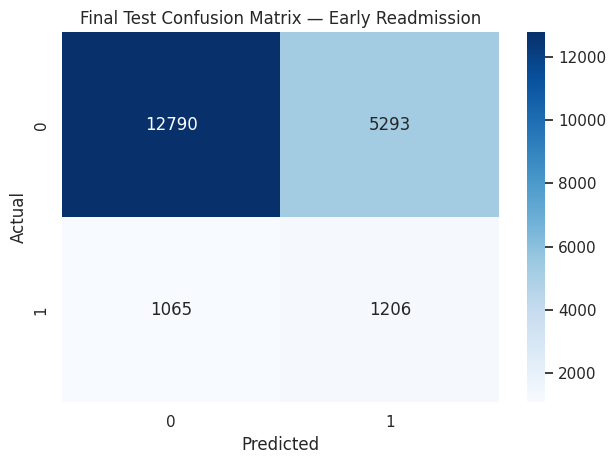

In [36]:

from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import seaborn as sns
import matplotlib.pyplot as plt

# Predict probabilities on the untouched test set
test_prob = balanced_rf_final.predict_proba(X2_test)
positive_index = list(balanced_rf_final.classes_).index(1)
test_prob = test_prob[:, positive_index]

# Apply threshold selected on validation data
test_pred = (test_prob >= best_threshold).astype(int)

print("FINAL TEST RESULTS — 30-DAY READMISSION")
print("Threshold:", best_threshold)
print("Accuracy:", round(accuracy_score(y2_test, test_pred), 4))
print("Precision:", round(
    precision_score(y2_test, test_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y2_test, test_pred, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y2_test, test_pred, zero_division=0), 4
))
print("ROC-AUC:", round(roc_auc_score(y2_test, test_prob), 4))

print("\nClassification report:")
print(classification_report(y2_test, test_pred, zero_division=0))

cm = confusion_matrix(y2_test, test_pred, labels=[0, 1])

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Final Test Confusion Matrix — Early Readmission")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


In [37]:

import os
import pandas as pd
import joblib
from sklearn.metrics import confusion_matrix

output_dir = "/content/healthcare_project/results"
os.makedirs(output_dir, exist_ok=True)

final_metrics = pd.DataFrame([{
    "Model": "Balanced Random Forest — Tuned Threshold",
    "Threshold": best_threshold,
    "Accuracy": accuracy_score(y2_test, test_pred),
    "Precision": precision_score(
        y2_test, test_pred, zero_division=0
    ),
    "Recall": recall_score(
        y2_test, test_pred, zero_division=0
    ),
    "F1_score": f1_score(
        y2_test, test_pred, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y2_test, test_prob)
}])

final_metrics.to_csv(
    f"{output_dir}/final_readmission_test_metrics.csv",
    index=False
)

pd.DataFrame(
    confusion_matrix(y2_test, test_pred, labels=[0, 1]),
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
).to_csv(f"{output_dir}/final_readmission_confusion_matrix.csv")

joblib.dump(
    balanced_rf_final,
    f"{output_dir}/balanced_readmission_tuned_model.joblib"
)

print("Final readmission evaluation saved.")
display(final_metrics.round(4))


Final readmission evaluation saved.


,Model,Threshold,Accuracy,Precision,Recall,F1_score,ROC_AUC
0,Balanced Random Forest — Tuned Threshold,0.4,0.6876,0.1856,0.531,0.275,0.6671


In [38]:

# Final diabetes model comparison using cross-validation results

display(
    cv_results_df.sort_values(
        "Mean CV Macro F1", ascending=False
    ).round(4)
)

best_diabetes_model_name = cv_results_df.iloc[0]["Model"]

print("Best diabetes model by cross-validation:",
      best_diabetes_model_name)

print("\nWeighted ensemble CV macro F1:",
      round(
          cv_results_df.loc[
              cv_results_df["Model"] == "Weighted Ensemble",
              "Mean CV Macro F1"
          ].iloc[0],
          4
      ))


,Model,Mean CV Macro F1,Std CV Macro F1
0,Logistic Regression,0.4211,0.0019
4,Balanced Logistic Regression,0.4211,0.0019
3,Weighted Ensemble,0.4017,0.0004
2,Extra Trees,0.3824,0.0011
1,Random Forest,0.3768,0.0010


Best diabetes model by cross-validation: Logistic Regression

Weighted ensemble CV macro F1: 0.4017


In [39]:

import os
import pandas as pd

output_dir = "/content/healthcare_project/results"
os.makedirs(output_dir, exist_ok=True)

# Combine the existing model comparison results
all_results = results.copy()

# Add the final tuned readmission model result
all_results = pd.concat(
    [
        all_results,
        pd.DataFrame([{
            "Dataset": "30-Day Readmission",
            "Model": "Balanced Random Forest — Tuned Threshold",
            "Accuracy": accuracy_score(y2_test, test_pred),
            "Precision_macro": precision_score(
                y2_test, test_pred, average="macro", zero_division=0
            ),
            "Recall_macro": recall_score(
                y2_test, test_pred, average="macro", zero_division=0
            ),
            "F1_macro": f1_score(
                y2_test, test_pred, average="macro", zero_division=0
            ),
            "ROC_AUC": roc_auc_score(y2_test, test_prob),
            "Specificity": (
                confusion_matrix(y2_test, test_pred, labels=[0, 1])[0, 0]
                / confusion_matrix(y2_test, test_pred, labels=[0, 1])[0].sum()
            )
        }])
    ],
    ignore_index=True
)

all_results.to_csv(
    f"{output_dir}/complete_project_results.csv",
    index=False
)

display(all_results.round(4))
print("Combined project results saved.")


,Dataset,Model,Accuracy,Precision_macro,Recall_macro,F1_macro,ROC_AUC,Specificity
0,Diabetes Status,Logistic Regression,0.6292,0.4475,0.5135,0.4257,0.7607,NaN
1,Diabetes Status,Random Forest,0.8231,0.4376,0.3734,0.3771,0.7142,NaN
2,Diabetes Status,Extra Trees,0.8111,0.4189,0.3757,0.3805,0.6920,NaN
3,Diabetes Status,Proposed Ensemble,0.8197,0.4405,0.3945,0.4030,0.7398,NaN
4,30-Day Readmission,Logistic Regression,0.6418,0.5430,0.6011,0.5095,0.6440,0.6535
5,30-Day Readmission,Random Forest,0.8887,0.7602,0.5024,0.4757,0.6511,0.9996
6,30-Day Readmission,Extra Trees,0.8888,0.7255,0.5064,0.4843,0.6345,0.9986
7,30-Day Readmission,Proposed Ensemble,0.8892,0.7545,0.5079,0.4873,0.6653,0.9987
8,30-Day Readmission,Balanced Random Forest — Tuned Threshold,0.6876,0.5543,0.6192,0.5380,0.6671,0.7073


Combined project results saved.


In [40]:

from sklearn.metrics import recall_score, f1_score, precision_score

# Original ensemble at its default threshold
ensemble_pred = fitted2["Proposed Ensemble"].predict(X2_test)

# Tuned balanced Random Forest at validation-selected threshold
tuned_pred = test_pred

final_readmission_comparison = pd.DataFrame([
    {
        "Model": "Original Ensemble",
        "Precision": precision_score(
            y2_test, ensemble_pred, zero_division=0
        ),
        "Recall": recall_score(
            y2_test, ensemble_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y2_test, ensemble_pred, zero_division=0
        )
    },
    {
        "Model": "Tuned Balanced Random Forest",
        "Precision": precision_score(
            y2_test, tuned_pred, zero_division=0
        ),
        "Recall": recall_score(
            y2_test, tuned_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y2_test, tuned_pred, zero_division=0
        )
    }
])

display(final_readmission_comparison.round(4))


,Model,Precision,Recall,F1-score
0,Original Ensemble,0.6190,0.0172,0.0334
1,Tuned Balanced Random Forest,0.1856,0.5310,0.2750


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os
import shutil

source = "/content/healthcare_project"
destination = "/content/drive/MyDrive/healthcare_project"

os.makedirs(os.path.dirname(destination), exist_ok=True)

if os.path.exists(source):
    if os.path.exists(destination):
        shutil.copytree(source, destination, dirs_exist_ok=True)
    else:
        shutil.copytree(source, destination)

    print("Project files copied to Google Drive!")
    print("Location:", destination)
    for root, dirs, files in os.walk(destination):
        for file in files:
            print(os.path.join(root, file))
else:
    print("Project folder not found. Check the current Colab runtime.")


Mounted at /content/drive
